# Variance Partitioning — Protein Level (variancePartition)

Quantifies how much of the variability in protein-level log₂ intensities is explained by technical versus biological factors using the `variancePartition` framework [(Hoffman & Schadt 2016)](https://doi.org/10.1186/s12859-016-1323-z). This complements the precursor-level scplainer analysis in `01_scplainer.ipynb` by operating at the protein level with a mixed-effects model that explicitly accounts for the nested plate/lab structure.

**Key differences from `01_scplainer.ipynb`:**

| Aspect | scplainer (`01_scplainer.ipynb`) | variancePartition (this notebook) |
|---|---|---|
| Feature level | Precursor | Protein |
| Model framework | scplainer linear model | `lme4` mixed-effects via `fitExtractVarPartModel` |
| Random effects | No (all fixed) | Yes — plate, date, plate × position |
| Missing values | Excluded (Diameter) / n/p filter | Row-mean imputed after protein filter |

**Modelling design — formula covariates:**

| Term | Type | Role |
|---|---|---|
| `(1\|plate_id)` | Random | Plate-level batch effect |
| `(0 + X_pos \| plate_id)` | Random slope | Plate-specific injection-position gradient |
| `(1\|plate_id:date)` | Random (nested) | Acquisition-day effect within plate |
| `injection_order_z` | Fixed | Within-plate run order (continuous, z-scored) |
| `(1\|source name)` | Random | Cell type — biological contrast of interest |
| `Diameter_z` | Fixed | Cell diameter from cellenONE (continuous, z-scored) [Dropped due to missing values] |
| `n_proteins_z` | Fixed | Number of identified proteins — normalisation proxy |
| `log2_median_intensity_z` | Fixed | Median log₂ intensity — normalisation proxy |

**Inputs** (`Data/AnnData/out/`)

| File | Description |
|---|---|
| `adata_protein.h5ad` | Protein-level log₂ intensities in `layers["X_log2"]`; `obs` carries all sample metadata |

**Outputs** (`Data/variancePartition/`)

| File | Description |
|---|---|
| `vp_fit.rds` | variancePartition result — full model |
| `vp_fit_norm.rds` | variancePartition result — after normalisation regression |
| `vp_fit_batch.rds` | variancePartition result — after full batch regression |
| `variance_fractions_full.csv` | Per-protein variance fractions, full model |

---

## Imports

In [1]:
library(reticulate)
use_condaenv("r44_varpart", required = TRUE)
py_config()
library(anndata)

pkgs <- c(
    "anndata", "reticulate",
    "reformulas",
    "variancePartition", "BiocParallel",
    "limma", "lme4",
    "ggplot2", "patchwork", "pheatmap",
    "RColorBrewer", "scales",
    "tidyr", "dplyr"
)

cat("Package check\n")
cat(strrep("─", 40), "\n")
for (p in pkgs) {
    status  <- requireNamespace(p, quietly = TRUE)
    version <- if (status) as.character(packageVersion(p)) else "MISSING"
    cat(sprintf("  %-25s %s\n", p, version))
}
cat("\n")

suppressPackageStartupMessages({
    invisible(lapply(pkgs, library, character.only = TRUE))
})

# Parallel backend
if (.Platform$OS.type == "windows") {
    register(SnowParam(workers = 64))
} else {
    register(MulticoreParam(workers = 64))
}

library(reformulas)
loadNamespace("reformulas")  # force full namespace load
library(variancePartition)

source("../../SCI_R/plotting_utils.R")
source("../../SCI_R/scplainer_plots.R")
source("../../SCI_R/varpart_plots.R")

python:         /home/sam/miniconda3/envs/r44_varpart/bin/python
libpython:      /home/sam/miniconda3/envs/r44_varpart/lib/libpython3.14.so
pythonhome:     /home/sam/miniconda3/envs/r44_varpart:/home/sam/miniconda3/envs/r44_varpart
version:        3.14.4 | packaged by conda-forge | (main, Apr  8 2026, 01:59:35) [GCC 14.3.0]
numpy:          /home/sam/miniconda3/envs/r44_varpart/lib/python3.14/site-packages/numpy
numpy_version:  2.4.3

NOTE: Python version was forced by use_python() function

Package check
──────────────────────────────────────── 
  anndata                   0.7.5.6
  reticulate                1.46.0
  reformulas                0.4.4
  variancePartition         1.36.2
  BiocParallel              1.40.0
  limma                     3.62.1
  lme4                      1.1.38
  ggplot2                   4.0.3
  patchwork                 1.3.2
  pheatmap                  1.0.13
  RColorBrewer              1.1.3
  scales                    1.4.0
  tidyr                     1.3.2
  dplyr                     1.2.1



<environment: namespace:reformulas>

## 0. Path Configuration

Output directories are resolved relative to the notebook location and created automatically if absent. Both can be overridden via environment variables for CI or cross-machine runs.

| Variable | Default | Environment override |
|---|---|---|
| `ROOT_OUT` | `../../Data` | `SCI_DATA_DIR` |
| `FIGURES_OUT` | `../../Figures` | `SCI_FIGURES_DIR` |

Model RDS files are written to `ROOT_OUT/variancePartition/` and read back from there in later sections. AnnData objects are read from `ROOT_OUT/AnnData/out/`, produced by the QC pipeline.

In [2]:
NOTEBOOK_DIR <- normalizePath(getwd())
ROOT_OUT     <- normalizePath(file.path(NOTEBOOK_DIR, "../../Data"))
ROOT_OUT     <- Sys.getenv("SCI_DATA_DIR",    unset = ROOT_OUT)

FIGURES_OUT  <- normalizePath(file.path(NOTEBOOK_DIR, "../../Figures/DIANN/second_pass"))
FIGURES_OUT  <- Sys.getenv("SCI_FIGURES_DIR", unset = FIGURES_OUT)

ANNDATA_IN  <- file.path(ROOT_OUT, "AnnData", "DIANN", "second_pass", "out")
MODELS_OUT  <- file.path(ROOT_OUT, "variancePartition", "DIANN")
FIG_OUT     <- file.path(FIGURES_OUT, "Figure_6", "VariancePartition")

for (d in c(ANNDATA_IN, MODELS_OUT, FIG_OUT)) {
    dir.create(d, recursive = TRUE, showWarnings = FALSE)
}

cat(sprintf("Data directory    : %s\n", ROOT_OUT))
cat(sprintf("Figures directory : %s\n", FIGURES_OUT))
cat(sprintf("Models directory  : %s\n", MODELS_OUT))
cat(sprintf("AnnData input     : %s\n", ANNDATA_IN))

Data directory    : /home/sam/SCI/SCI/Data
Figures directory : /home/sam/SCI/SCI/Figures/DIANN/second_pass
Models directory  : /home/sam/SCI/SCI/Data/variancePartition/DIANN
AnnData input     : /home/sam/SCI/SCI/Data/AnnData/DIANN/second_pass/out


## 1. Load Data

Reads the protein-level AnnData object and extracts the log₂-transformed intensity matrix from `layers["X_log2"]`. The matrix is transposed to proteins × cells for compatibility with `variancePartition` and `limma`. Sample metadata from `obs` is extracted as `meta` and carries all covariates used in the model formula.

> The AnnData is expected to contain only cells that passed the upstream QC pipeline. No additional cell filtering is applied here.

In [3]:
adata    <- read_h5ad(file.path(ANNDATA_IN, "adata_protein.h5ad"))

expr_mat <- t(as.matrix(adata$layers['X_log2']))
var_meta <- adata$var
meta     <- adata$obs

# filter samples
keep_samples <- !meta[['completeness_outlier']] &
                meta[['source name']] %in% c('HEK293T', 'K562')
meta     <- meta[keep_samples, ]
expr_mat <- expr_mat[, keep_samples]

# filter features
keep_features <- !var_meta[['Contaminant']]
var_meta <- var_meta[keep_features, ]
expr_mat <- expr_mat[keep_features, ]

cat(sprintf("Samples  : %d → %d\n", ncol(t(as.matrix(adata$layers['X_log2']))), ncol(expr_mat)))
cat(sprintf("Features : %d → %d (removed %d contaminants)\n",
            nrow(t(as.matrix(adata$layers['X_log2']))),
            nrow(expr_mat),
            sum(!keep_features)))

cat(sprintf("Proteins x cells : %d x %d\n", nrow(expr_mat), ncol(expr_mat)))
cat(sprintf("NA values        : %d  (%.1f%%)\n",
            sum(is.na(expr_mat)),
            100 * mean(is.na(expr_mat))))
cat("\nMetadata columns:\n")
print(colnames(meta))

Samples  : 2587 → 1671
Features : 6321 → 6135 (removed 186 contaminants)
Proteins x cells : 6135 x 1671
NA values        : 7855376  (76.6%)

Metadata columns:
 [1] "Run"                             "sample_name"                    
 [3] "plate_id"                        "plate_idx"                      
 [5] "source name"                     "comment[X position]"            
 [7] "comment[Y position]"             "comment[Plate Number]"          
 [9] "comment[Gradient time]"          "comment[thawing timepoint]"     
[11] "comment[plate arrival]"          "injection_order"                
[13] "institute_name"                  "Reinjection"                    
[15] "Diameter"                        "Elongation"                     
[17] "Circularity"                     "Doublet"                        
[19] "Dividing"                        "Dying"                          
[21] "CellInBlank"                     "comment[plate arrival]_date"    
[23] "comment[plate arrival]_time"    

In [4]:
expr_mat[!is.finite(expr_mat)] <- NA

In [5]:
meta['log2_median_intensity'] <- rowMeans(t(expr_mat), na.rm = TRUE)

## 2. Parse Variables

Three preparatory steps derive the covariates needed for the mixed-effects model:

1. **Column definitions and type coercion** — column-name constants are defined once here and referenced throughout; categorical variables are converted to factors; continuous covariates are z-scored.
2. **Missing value audit** — `Diameter` (~11%) is the only covariate with structural missingness. Cells without a `Diameter` measurement are excluded from modelling (drops from the `meta` and `expr_mat` objects at the end of this section).

### 2.1 Column Definitions and Type Coercion

Column-name constants are defined once here so that formula construction and subsetting throughout the notebook reference the same strings. Categorical columns are converted to `factor` (required by `lme4` for random effects); continuous covariates are z-scored to put fixed-effect coefficients on a common scale and to improve numerical stability of the mixed-effects solver.

In [6]:
# Reset NAs
meta$Diameter[meta$Diameter == -1] <- NA

# Column-name constants
COL_CELL_TYPE       <- "source name"
COL_INSTRUMENT      <- "instrument_type"
COL_X_POSITION      <- "comment[X position]"
COL_Y_POSITION      <- "comment[Y position]"
COL_DIAMETER        <- "Diameter"
COL_N_PROTEINS      <- "n_proteins"
COL_LOG2_MED_INT    <- "log2_median_intensity"
COL_PLATE           <- "plate_idx"
COL_DATE            <- "comment[Gradient time]_date"
COL_INJ_ORDER       <- "injection_order"

required_cols <- c(COL_CELL_TYPE, COL_INSTRUMENT, COL_X_POSITION, COL_Y_POSITION,
                   COL_DIAMETER, COL_N_PROTEINS, COL_LOG2_MED_INT,
                   COL_PLATE, COL_DATE, COL_INJ_ORDER)
missing_cols <- setdiff(required_cols, colnames(meta))
if (length(missing_cols) > 0) {
    stop("Missing columns in obs: ", paste(missing_cols, collapse = ", "))
}
cat("All required columns present.\n\n")

# Factors
meta[[COL_CELL_TYPE]]  <- factor(meta[[COL_CELL_TYPE]])
meta[[COL_INSTRUMENT]] <- factor(meta[[COL_INSTRUMENT]])
meta[[COL_PLATE]]      <- factor(meta[[COL_PLATE]])
meta[[COL_DATE]]       <- factor(meta[[COL_DATE]])

# Continuous
meta[[COL_DIAMETER]]     <- as.numeric(meta[[COL_DIAMETER]])
meta[[COL_N_PROTEINS]]   <- as.numeric(meta[[COL_N_PROTEINS]])
meta[[COL_LOG2_MED_INT]] <- as.numeric(meta[[COL_LOG2_MED_INT]])

# Z-scores (used in formulas; keeps original columns intact)
meta$Diameter_z              <- scale(meta[[COL_DIAMETER]])[, 1]
meta$n_proteins_z            <- scale(meta[[COL_N_PROTEINS]])[, 1]
meta$log2_median_intensity_z <- scale(meta[[COL_LOG2_MED_INT]])[, 1]
meta$injection_order_z       <- scale(meta[[COL_INJ_ORDER]])[, 1]
meta$X_position_z            <- scale(meta[[COL_X_POSITION]])[, 1]

# Rename the date column
meta$date <- meta[[COL_DATE]]
COL_DATE <- "date"          

cat("Type summary:\n")
type_summary <- sapply(required_cols, function(v) class(meta[[v]]))
print(type_summary)

All required columns present.



Type summary:
                source name             instrument_type 
                   "factor"                    "factor" 
        comment[X position]         comment[Y position] 
                  "numeric"                   "numeric" 
                   Diameter                  n_proteins 
                  "numeric"                   "numeric" 
      log2_median_intensity                   plate_idx 
                  "numeric"                    "factor" 
comment[Gradient time]_date             injection_order 
                   "factor"                   "numeric" 


### 2.2 Missing Value Audit and Cell Exclusion

Checks all model covariates for `NA` values. `Diameter` (~11%) is the only covariate with structural missingness, caused by cells that could not be imaged by the cellenONE. Mean imputation would attenuate the estimated `Diameter` effect and bias the variance decomposition, so cells without a `Diameter` measurement are excluded from both `meta` and `expr_mat` before modelling. All cells are retained above for injection-order computation and type coercion.

> Protein-level missing values (sparse detection across cells) are handled separately in Section 5.1 via row-mean imputation, which is standard practice for `fitExtractVarPartModel`.

In [7]:
formula_vars <- c(COL_CELL_TYPE, COL_INSTRUMENT, COL_X_POSITION,
                  COL_N_PROTEINS, COL_LOG2_MED_INT,
                  COL_PLATE, COL_DATE, COL_INJ_ORDER)

na_summary <- sapply(formula_vars, function(v) {
    x <- meta[[v]]
    c(n_NA = sum(is.na(x)), pct_NA = round(mean(is.na(x)) * 100, 1), n_total = length(x))
})
print(t(na_summary))

# Exclude cells with missing Diameter
complete_cells <- !is.na(meta[[COL_DIAMETER]])
# meta     <- meta[complete_cells, ]
# expr_mat <- expr_mat[, complete_cells]

cat(sprintf("\nCells with Diameter measurement : %d / %d  (%.1f%% retained)\n",
            nrow(meta) - sum(!complete_cells), nrow(meta),
            100 * mean(complete_cells)))
cat(sprintf("expr_mat dimensions             : %d proteins x %d cells\n",
            nrow(expr_mat), ncol(expr_mat)))

                      n_NA pct_NA n_total
source name              0      0    1671
instrument_type          0      0    1671
comment[X position]      0      0    1671
n_proteins               0      0    1671
log2_median_intensity    0      0    1671
plate_idx                0      0    1671
date                     0      0    1671
injection_order          0      0    1671

Cells with Diameter measurement : 1483 / 1671  (88.7% retained)
expr_mat dimensions             : 6135 proteins x 1671 cells


## 3. Protein Filtering

`fitExtractVarPartModel` requires each protein to be quantified in enough cells and across enough plates to estimate the random-effect variance components reliably. A protein that is only detected in one plate contributes no information to the plate random effect and will cause fitting errors.

Two thresholds control retention:

| Parameter | Default | Meaning |
|---|---|---|
| `min_cell_pct` | 25% | A protein must be detected in ≥ 25% of cells *within a plate* for that plate to count |
| `min_n_plates` | 5 | A protein must pass the cell-fraction threshold in at least 5 of the 9 plates |

The heatmap below shows the percentage of proteins retained across a grid of threshold combinations, helping to identify a threshold that balances stringency against proteome coverage.

### 3.1 Retention Heatmap

Each cell shows the percentage of proteins that would be retained at that combination of cell-fraction threshold (x-axis) and minimum number of plates (y-axis). Use this to validate that the chosen defaults (25%, 5 plates) sit in a reasonable region — not so loose that poorly-detected proteins dominate the model fit, not so strict that the proteome coverage drops below ~50%.

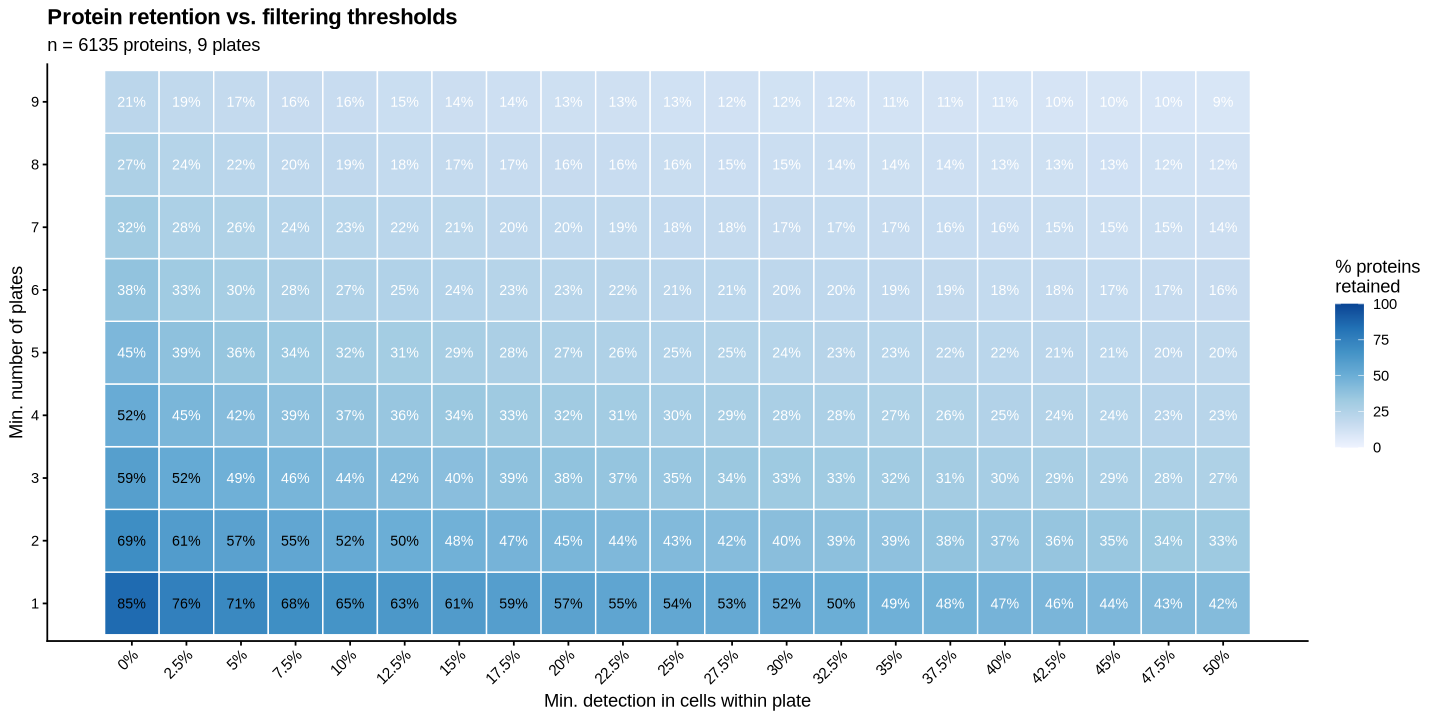

In [8]:
plates   <- levels(meta[[COL_PLATE]])
n_plates <- length(plates)

# Per-protein, per-plate detection fraction
plate_comp_mat <- sapply(plates, function(plate) {
    idx    <- which(meta[[COL_PLATE]] == plate)
    m      <- expr_mat[, idx, drop = FALSE]
    comp   <- rowMeans(!is.na(m))
    comp[rowSums(!is.na(m)) == 0] <- NA   # protein absent from plate entirely
    comp
})  # n_proteins x n_plates

cell_thresholds  <- seq(0, 0.5, by = 0.025)
plate_thresholds <- seq_len(n_plates)

retention_grid <- outer(cell_thresholds, plate_thresholds, Vectorize(function(ct, pt) {
    passes <- plate_comp_mat >= ct
    mean(rowSums(passes, na.rm = TRUE) >= pt) * 100
}))

df_heatmap <- expand.grid(min_cells_pct = cell_thresholds * 100,
                           min_plates    = plate_thresholds) %>%
    mutate(retention = as.vector(retention_grid))

options(repr.plot.width = 12, repr.plot.height = 6)

ggplot(df_heatmap, aes(x = min_cells_pct, y = factor(min_plates), fill = retention)) +
    geom_tile(colour = "white", linewidth = 0.4) +
    geom_text(aes(label  = sprintf("%.0f%%", retention),
                  colour = retention > 50),
              size = 3) +
    scale_colour_manual(values = c("TRUE" = "black", "FALSE" = "white"), guide = "none") +
    scale_fill_distiller(palette = "Blues", direction = 1,
                         limits = c(0, 100), name = "% proteins\nretained") +
    scale_x_continuous(breaks = cell_thresholds * 100,
                       labels = paste0(cell_thresholds * 100, "%")) +
    theme_classic(base_size = 11) +
    labs(title    = "Protein retention vs. filtering thresholds",
         subtitle = sprintf("n = %d proteins, %d plates", nrow(expr_mat), n_plates),
         x        = "Min. detection in cells within plate",
         y        = "Min. number of plates") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1),
          plot.title  = element_text(face = "bold"))

### 3.2 Apply Filter

Applies the chosen thresholds. Proteins that do not meet the criteria are removed from `expr_mat` for all downstream steps.

In [9]:
filter_proteins <- function(expr_mat, meta, col_plate,
                             min_cell_pct = 0.3,
                             min_n_plates = 6) {
    plates     <- levels(meta[[col_plate]])
    plate_comp <- sapply(plates, function(plate) {
        idx  <- which(meta[[col_plate]] == plate)
        m    <- expr_mat[, idx, drop = FALSE]
        comp <- rowMeans(!is.na(m))
        comp[rowSums(!is.na(m)) == 0] <- NA
        comp
    })

    passes           <- plate_comp >= min_cell_pct
    n_plates_passing <- rowSums(passes, na.rm = TRUE)
    keep             <- n_plates_passing >= min_n_plates

    cat(sprintf("Protein filter:\n"))
    cat(sprintf("  Min. %% cells within plate : %.0f%%\n",   min_cell_pct * 100))
    cat(sprintf("  Min. number of plates     : %d / %d\n",  min_n_plates, length(plates)))
    cat(sprintf("  Proteins before           : %d\n",       nrow(expr_mat)))
    cat(sprintf("  Proteins after            : %d  (%.1f%% retained)\n",
                sum(keep), 100 * mean(keep)))

    expr_mat[keep, ]
}

MIN_CELL_PCT <- 0.3
MIN_N_PLATES <- 6

expr_mat <- filter_proteins(expr_mat, meta,
                             col_plate    = COL_PLATE,
                             min_cell_pct = MIN_CELL_PCT,
                             min_n_plates = MIN_N_PLATES)

Protein filter:
  Min. % cells within plate : 30%
  Min. number of plates     : 6 / 9
  Proteins before           : 6135
  Proteins after            : 1236  (20.1% retained)


In [10]:
meta['log2_median_intensity'] <- rowMeans(t(expr_mat), na.rm = TRUE)

## 4. Fitting Models

Fits three `variancePartition` models corresponding to successive correction stages. The workflow mirrors `01_scplainer.ipynb`: each stage regresses out a subset of technical effects, and the residuals are passed to the next model. This isolates how much variance each covariate group explains *on top of* effects already removed.

| Stage | Input matrix | Regressed out (via `lmFit`) | Model formula |
|---|---|---|---|
| `vp_fit` | Raw log₂ intensities | — | All effects |
| `vp_fit_norm` | Norm-corrected residuals | `log2_median_intensity + n_proteins` | Batch + biology |
| `vp_fit_batch` | Batch-corrected residuals | Norm + plate + position + injection | Biology only |

<br>

> **Runtime note** — each `fitExtractVarPartModel` call takes ~30–60 minutes on 64 cores. RDS files are written after each fit so later sections can be run independently.

### 4.1 Row-mean Imputation

`fitExtractVarPartModel` cannot handle missing values in the expression matrix. After protein filtering, each remaining `NA` (protein detected in some cells but not others) is replaced with the per-protein row mean. This preserves the mean expression level while filling gaps with the least informative value. Proteins that survived the filter are guaranteed to have at least one valid observation per plate (by construction), so row means are always well-defined.

In [11]:
cat(sprintf("NAs before imputation: %d  (%.1f%%)\n",
            sum(is.na(expr_mat)), 100 * mean(is.na(expr_mat))))

expr_mat_impute <- t(apply(expr_mat, 1, function(x) {
    x[is.na(x)] <- mean(x, na.rm = TRUE)
    x
}))

cat(sprintf("NAs after  imputation: %d\n", sum(is.na(expr_mat_impute))))
cat(sprintf("Matrix dimensions    : %d proteins x %d cells\n",
            nrow(expr_mat_impute), ncol(expr_mat_impute)))

NAs before imputation: 410182  (19.9%)
NAs after  imputation: 0
Matrix dimensions    : 1236 proteins x 1671 cells


### 4.2 Model Formulas

Three formulas are defined, one per correction stage. Each formula only includes covariates that are *not* already regressed out in the input matrix, so that the variance fractions sum to ~100% and are interpretable.

| Formula | Stage | Covariates included |
|---|---|---|
| `vp_formula` | Full (no correction) | All normalisation + batch + biology terms |
| `vp_formula_norm` | Post-normalisation | Batch + biology (normalisation already removed) |
| `vp_formula_batch` | Post-batch | Biology only (`source name`) |

**Design note** — in `variancePartition`, categorical variables enter as random effects `(1|var)` because the framework treats all grouping variables symmetrically. Continuous fixed effects (`Diameter_z`, `injection_order_z`, etc.) enter as standard fixed-effects terms. The nested random slope `(0 + X_pos | plate_id)` models a per-plate linear gradient in injection position without a plate-level intercept shift (the intercept is captured by `(1|plate_id)`).

In [12]:
# Full model — all technical and biological effects
vp_formula <- as.formula(
    "~ (1 | plate_idx) +
       (0 + `comment[X position]` | plate_idx) +
       (1 | plate_idx:date) +
       injection_order_z +
       (1 | `source name`) +
       n_proteins_z +
       log2_median_intensity_z"
)

# After normalisation regression — drop n_proteins + log2_median_intensity terms
vp_formula_norm <- as.formula(
    "~ (1 | plate_idx) +
       (0 + `comment[X position]` | plate_idx) +
       (1 | plate_idx:date) +
       injection_order_z +
       (1 | `source name`)"
)

vp_formula_plate <- as.formula(
    "~ (0 + `comment[X position]` | plate_idx) +
       (1 | plate_idx:date) +
        injection_order_z +
       (1 | `source name`)"
)

# After full batch regression — only biology remains
vp_formula_batch <- as.formula(
    "~ (1 | `source name`)"
)

cat("Formulas defined.\n")
print(vp_formula)

Formulas defined.
~(1 | plate_idx) + (0 + `comment[X position]` | plate_idx) + 
    (1 | plate_idx:date) + injection_order_z + (1 | `source name`) + 
    n_proteins_z + log2_median_intensity_z


### 4.3 Batch Correction via `lmFit`

Regresses out technical effects from `expr_mat_impute` using `limma::lmFit` before fitting the reduced-formula variancePartition models. Using `lmFit` residuals rather than simply dropping terms from the formula ensures that the regressed-out variance is fully removed, not just diluted, in the residual matrix fed to the next model.

| Residual | Regressors removed |
|---|---|
| `res_norm` | `log2_median_intensity + n_proteins` |
| `res_batch` | `plate_id + log2_median_intensity + n_proteins + X_position + injection_order` |

**Caution** — `lmFit` uses a fixed-effects model for correction, which assumes each plate is a fixed level rather than a sample from a random distribution. This differs from the random-effect treatment in `vp_formula`. The residuals are used solely as inputs to reduced variancePartition models; the full model (`vp_fit`) uses the uncorrected matrix.

In [13]:
# Post-normalisation residuals
design_norm <- model.matrix(
    ~ log2_median_intensity + n_proteins,
    data = meta
)
fit_norm <- lmFit(expr_mat_impute, design_norm)
res_norm  <- residuals(fit_norm, expr_mat_impute)

design_plate <- model.matrix(
    as.formula(paste0(
        "~ plate_idx + log2_median_intensity + n_proteins"
    )),
    data = meta
)
fit_plate <- lmFit(expr_mat_impute, design_plate)
res_plate  <- residuals(fit_plate, expr_mat_impute)

# Post-batch residuals (normalisation + plate + position + injection order)
design_batch <- model.matrix(
    as.formula(paste0(
        "~ plate_idx + log2_median_intensity + n_proteins + `comment[X position]` + injection_order_z"
    )),
    data = meta
)
fit_batch <- lmFit(expr_mat_impute, design_batch)
res_batch  <- residuals(fit_batch, expr_mat_impute)

design_all <- model.matrix(
    as.formula(paste0(
        "~ plate_idx + log2_median_intensity + n_proteins + `comment[X position]` + injection_order_z + `source name`"
    )),
    data = meta
)
fit_all <- lmFit(expr_mat_impute, design_all)
res_all <- residuals(fit_all, expr_mat_impute)

cat(sprintf("res_norm  : %d x %d  (NAs: %d)\n",
            nrow(res_norm),  ncol(res_norm),  sum(is.na(res_norm))))
cat(sprintf("res_plate : %d x %d  (NAs: %d)\n",
            nrow(res_plate), ncol(res_plate), sum(is.na(res_plate))))
cat(sprintf("res_batch : %d x %d  (NAs: %d)\n",
            nrow(res_batch), ncol(res_batch), sum(is.na(res_batch))))
cat(sprintf("res_all : %d x %d  (NAs: %d)\n",
            nrow(res_all), ncol(res_all), sum(is.na(res_all))))

res_norm  : 1236 x 1671  (NAs: 0)
res_plate : 1236 x 1671  (NAs: 0)
res_batch : 1236 x 1671  (NAs: 0)
res_all : 1236 x 1671  (NAs: 0)


### 5.4 Fit variancePartition Models

Fits three models via `fitExtractVarPartModel`. Each returns a `varPartResults` data frame (proteins × covariates) giving the percentage of variance explained by each term. Models are saved to disk and results exported to CSV for easy inspection outside R.

In [ ]:
library(reformulas)

In [16]:
library(reformulas)

cat("[1/4] Fitting full model...\n")
vp_fit <- fitExtractVarPartModel(
    exprObj = expr_mat_impute,
    formula = vp_formula,
    data    = meta,
    BPPARAM = bpparam()
)
saveRDS(vp_fit, file.path(MODELS_OUT, "vp_fit.rds"))
write.csv(as.data.frame(vp_fit),
          file.path(MODELS_OUT, "variance_fractions_full.csv"),
          row.names = TRUE)
cat("  Saved: vp_fit.rds\n")

cat("[2/4] Fitting post-normalisation model...\n")
vp_fit_norm <- fitExtractVarPartModel(
    exprObj = res_norm,
    formula = vp_formula_norm,
    data    = meta,
    BPPARAM = bpparam()
)
saveRDS(vp_fit_norm, file.path(MODELS_OUT, "vp_fit_norm.rds"))
cat("  Saved: vp_fit_norm.rds\n")

cat("[3/4] Fitting post-plate model...\n")
vp_fit_plate <- fitExtractVarPartModel(
    exprObj = res_plate,
    formula = vp_formula_plate,
    data    = meta,
    BPPARAM = bpparam()
)
saveRDS(vp_fit_plate, file.path(MODELS_OUT, "vp_fit_plate.rds"))
cat("  Saved: vp_fit_plate.rds\n")

cat("[4/4] Fitting post-batch model...\n")
vp_fit_batch <- fitExtractVarPartModel(
    exprObj = res_batch,
    formula = vp_formula_batch,
    data    = meta,
    BPPARAM = bpparam()
)
saveRDS(vp_fit_batch, file.path(MODELS_OUT, "vp_fit_batch.rds"))
cat("  Saved: vp_fit_batch.rds\n")

[1/4] Fitting full model...


  Saved: vp_fit.rds
[2/4] Fitting post-normalisation model...
  Saved: vp_fit_norm.rds
[3/4] Fitting post-plate model...
  Saved: vp_fit_plate.rds
[4/4] Fitting post-batch model...
  Saved: vp_fit_batch.rds


## 6. Variance Distributions

`plotVarPart` (from `variancePartition`) draws a violin plot per covariate showing the distribution of per-protein variance fractions across all retained proteins. Covariates are sorted by median variance explained (highest first).

**Interpreting the progression across stages:**
- **Full model** — shows the raw decomposition. Expect normalisation terms (`log2_median_intensity`, `n_proteins`) and `plate_id` to dominate. Residual should be large if many unexplained sources remain.
- **Post-normalisation** — normalisation terms are removed; batch and biology terms should grow proportionally to fill the gap.
- **Post-batch** — only `source name` and `Diameter` remain; their combined fraction indicates how much of the variance is biological after full technical correction. A high residual here means unexplained cell-to-cell heterogeneity.

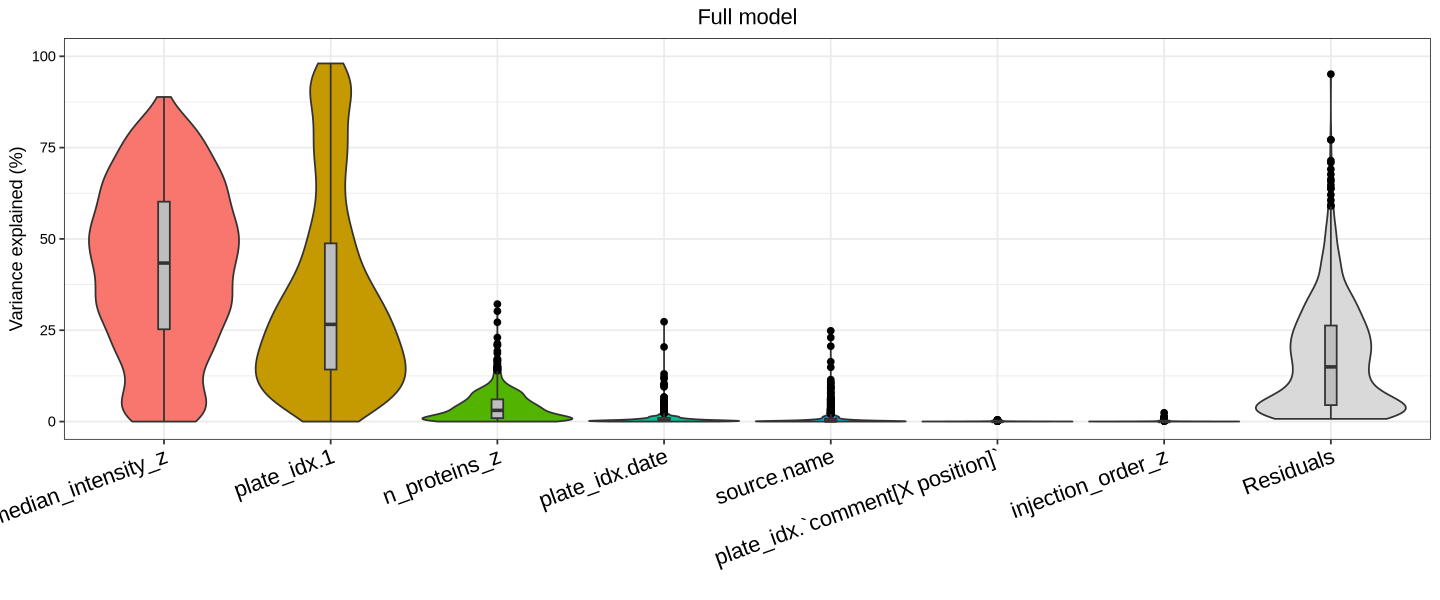

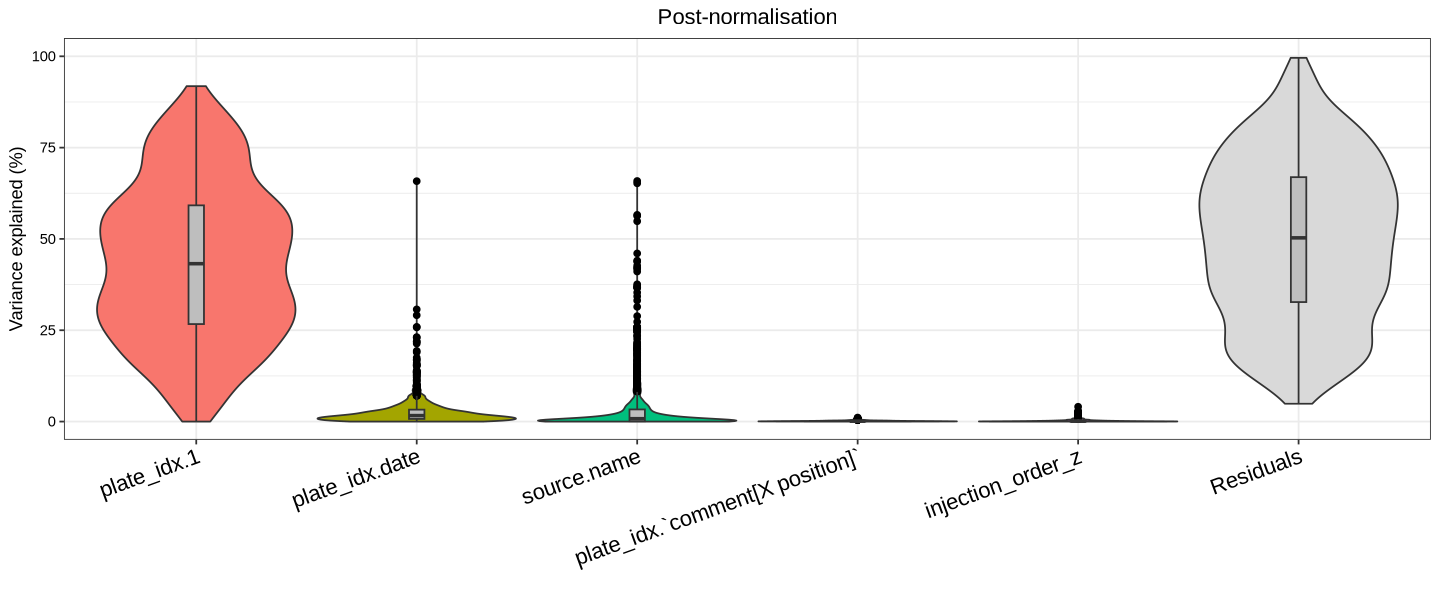

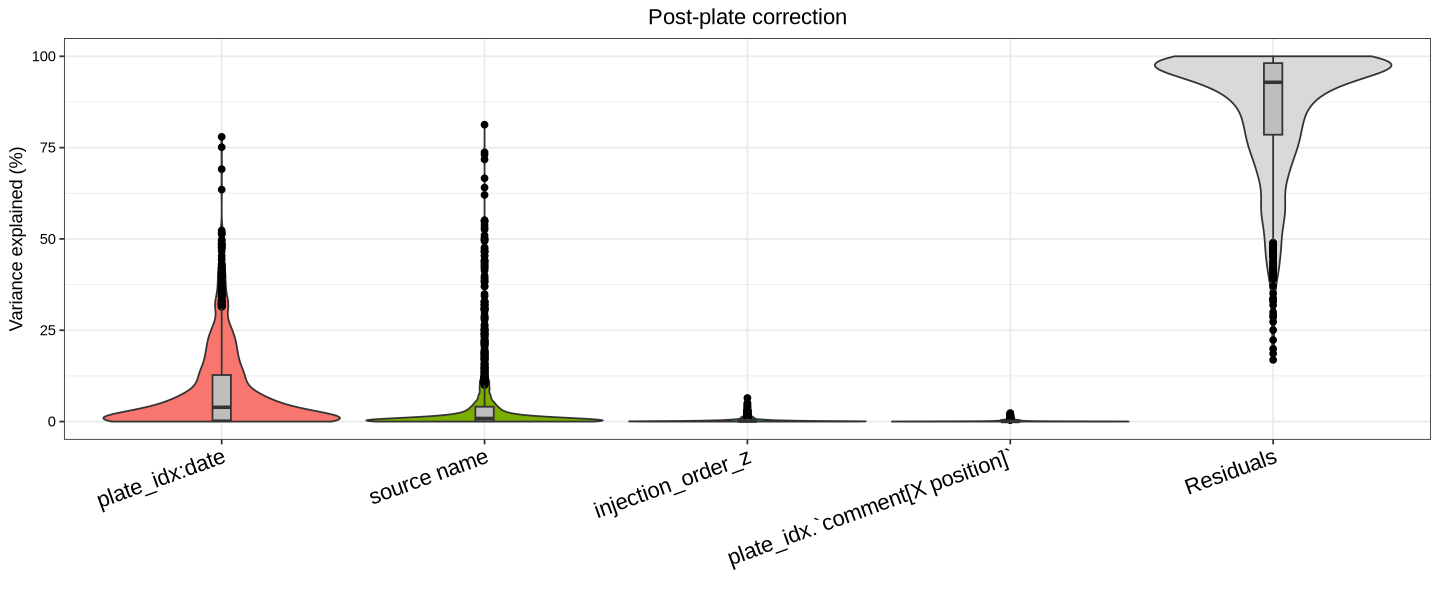

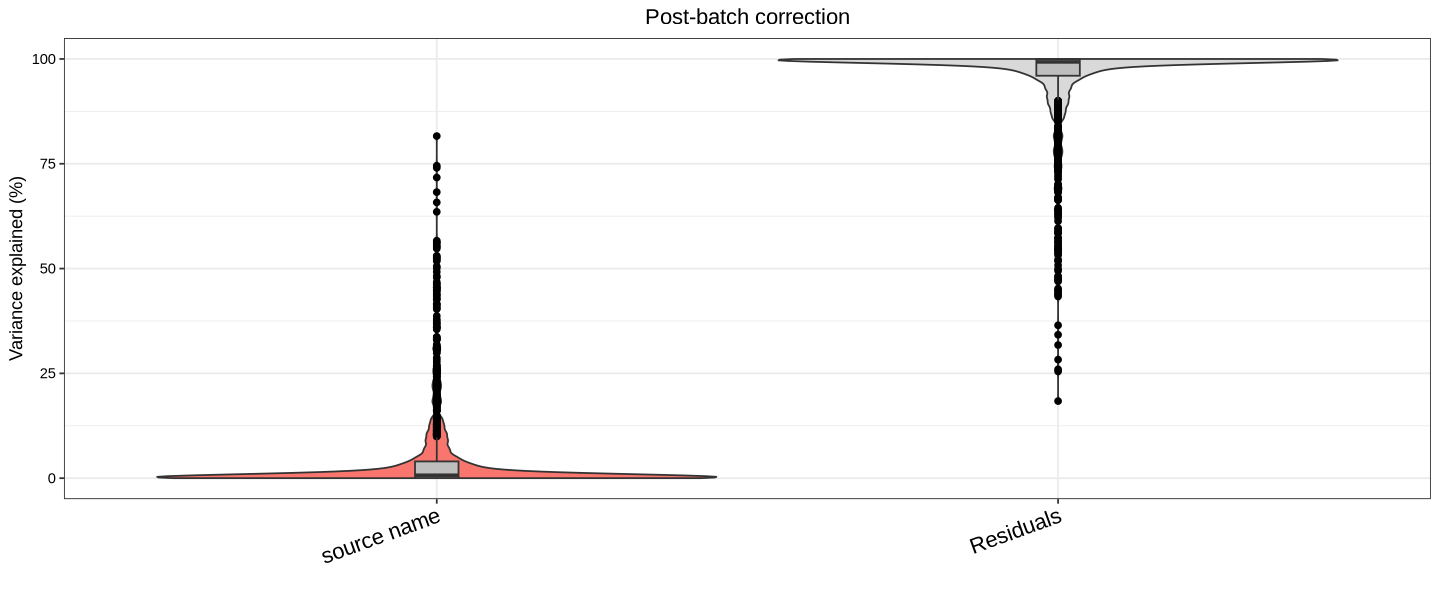

In [17]:
if (!exists("vp_fit"))       vp_fit       <- readRDS(file.path(MODELS_OUT, "vp_fit.rds"))
if (!exists("vp_fit_norm"))  vp_fit_norm  <- readRDS(file.path(MODELS_OUT, "vp_fit_norm.rds"))
if (!exists("vp_fit_plate")) vp_fit_plate <- readRDS(file.path(MODELS_OUT, "vp_fit_plate.rds"))
if (!exists("vp_fit_batch")) vp_fit_batch <- readRDS(file.path(MODELS_OUT, "vp_fit_batch.rds"))

vp_list <- list(
    "Full model"            = vp_fit,
    "Post-normalisation"    = vp_fit_norm,
    "Post-plate correction" = vp_fit_plate,
    "Post-batch correction" = vp_fit_batch
)

for (nm in names(vp_list)) {
    p        <- plotVarPart(sortCols(vp_list[[nm]])) + ggtitle(nm)
    filename <- paste0("varpart_", gsub(" ", "_", tolower(nm)))
    save_figure(p, file.path(FIG_OUT, filename), width = 12, height = 5)
    options(repr.plot.width = 12, repr.plot.height = 5)
    print(p)
    flush.console()
}

> **NOTE**: It's weird that all variance in the second plot is captured inside plate_idx:date and not in plate_idx. This is because both covariates are highly correlated with each other and using only plate_idx:date is just the same as plate_idx if only a single day is used to measure the samples for a particular plate. Additionally, even if the plate was acquired in multiple days, the model must decide how much variance is attributed to a stable lab-effect versus the day-to-day fluctuations of a particular plate. So in practice here, plate_idx.date and plate_idx are difficult to distniguish from each other and should be seen together.

## 7. Dimensionality Reduction

PCA on the corrected expression matrices provides a complementary visual validation of the variance decomposition. Three matrices are plotted:

| Matrix | What it shows |
|---|---|
| `expr_mat_impute` | Raw structure — expected to cluster by plate and instrument |
| `res_norm` | After normalisation correction — intensity-scale batch reduced |
| `res_batch` | After full batch correction — should show separation by cell type only |

Each matrix yields three plots coloured by `plate_id`, `source name`, and `comment[X position]` respectively. `prcomp` is applied after removing proteins with any remaining `NA` (in practice none after imputation).

Computing PCA: raw...


Warning message in brewer.pal(min(n, 9), "Set1"):
“minimal value for n is 3, returning requested palette with 3 different levels
”


Computing PCA: post_normalisation...


Warning message in brewer.pal(min(n, 9), "Set1"):
“minimal value for n is 3, returning requested palette with 3 different levels
”


Computing PCA: post plate correction...


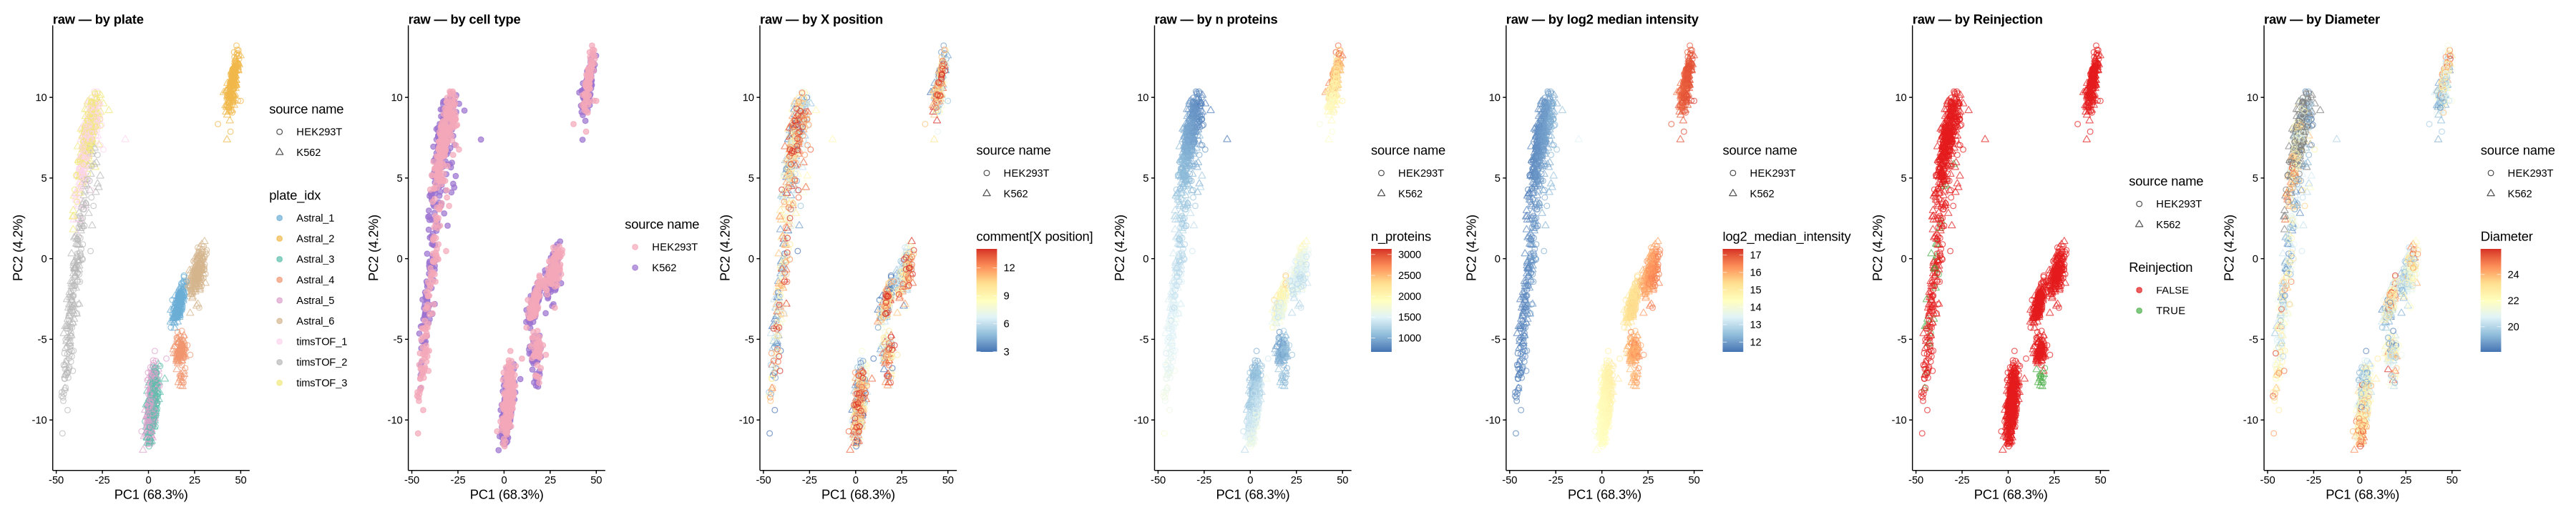

Warning message in brewer.pal(min(n, 9), "Set1"):
“minimal value for n is 3, returning requested palette with 3 different levels
”


Computing PCA: post_batch...


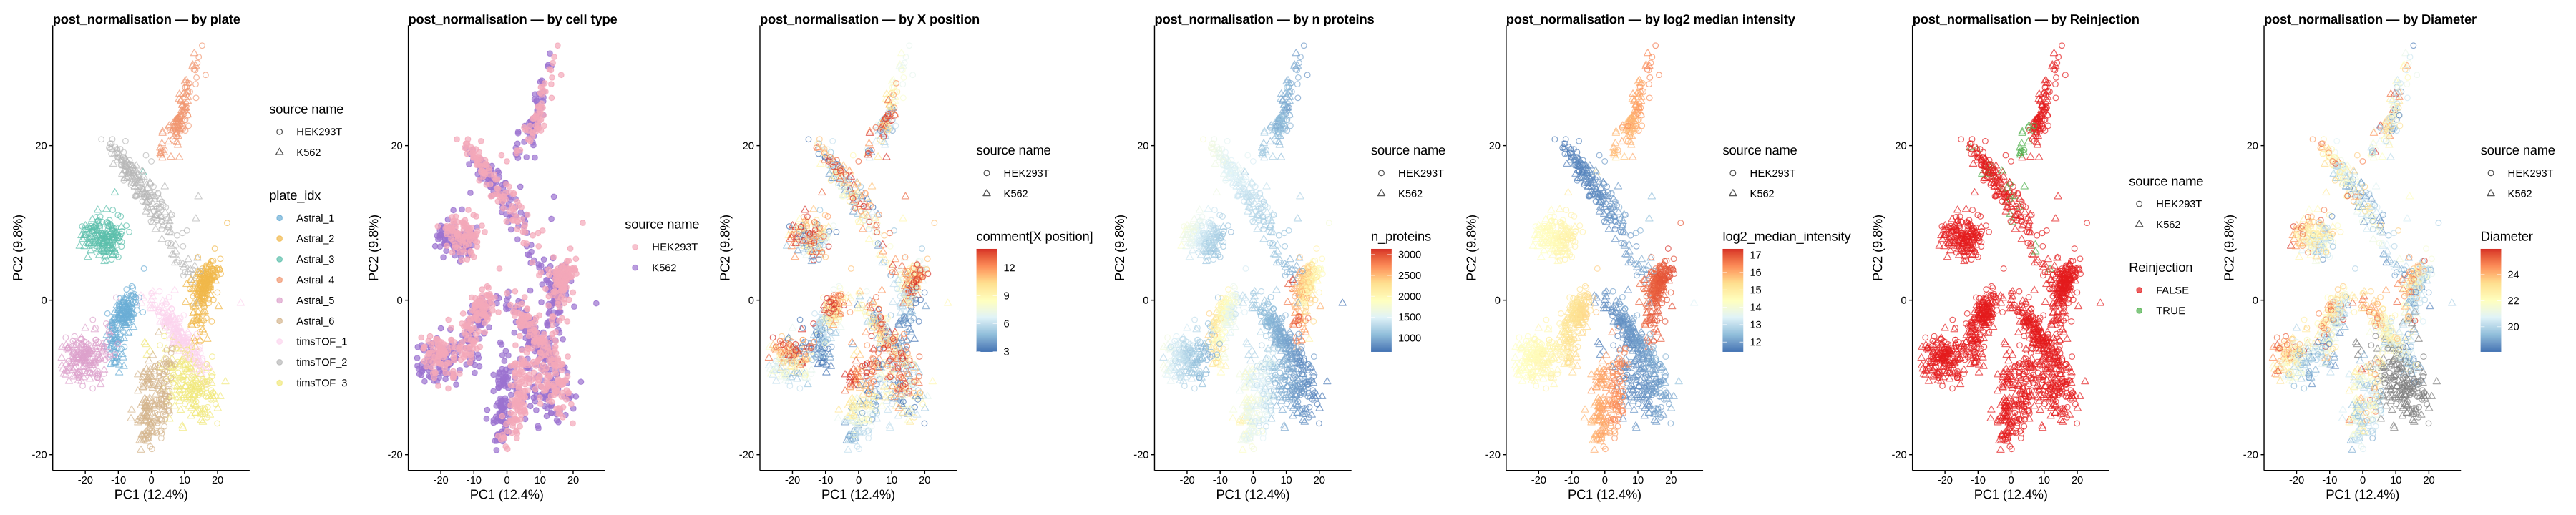

Warning message in brewer.pal(min(n, 9), "Set1"):
“minimal value for n is 3, returning requested palette with 3 different levels
”


Computing PCA: post_full_regression...


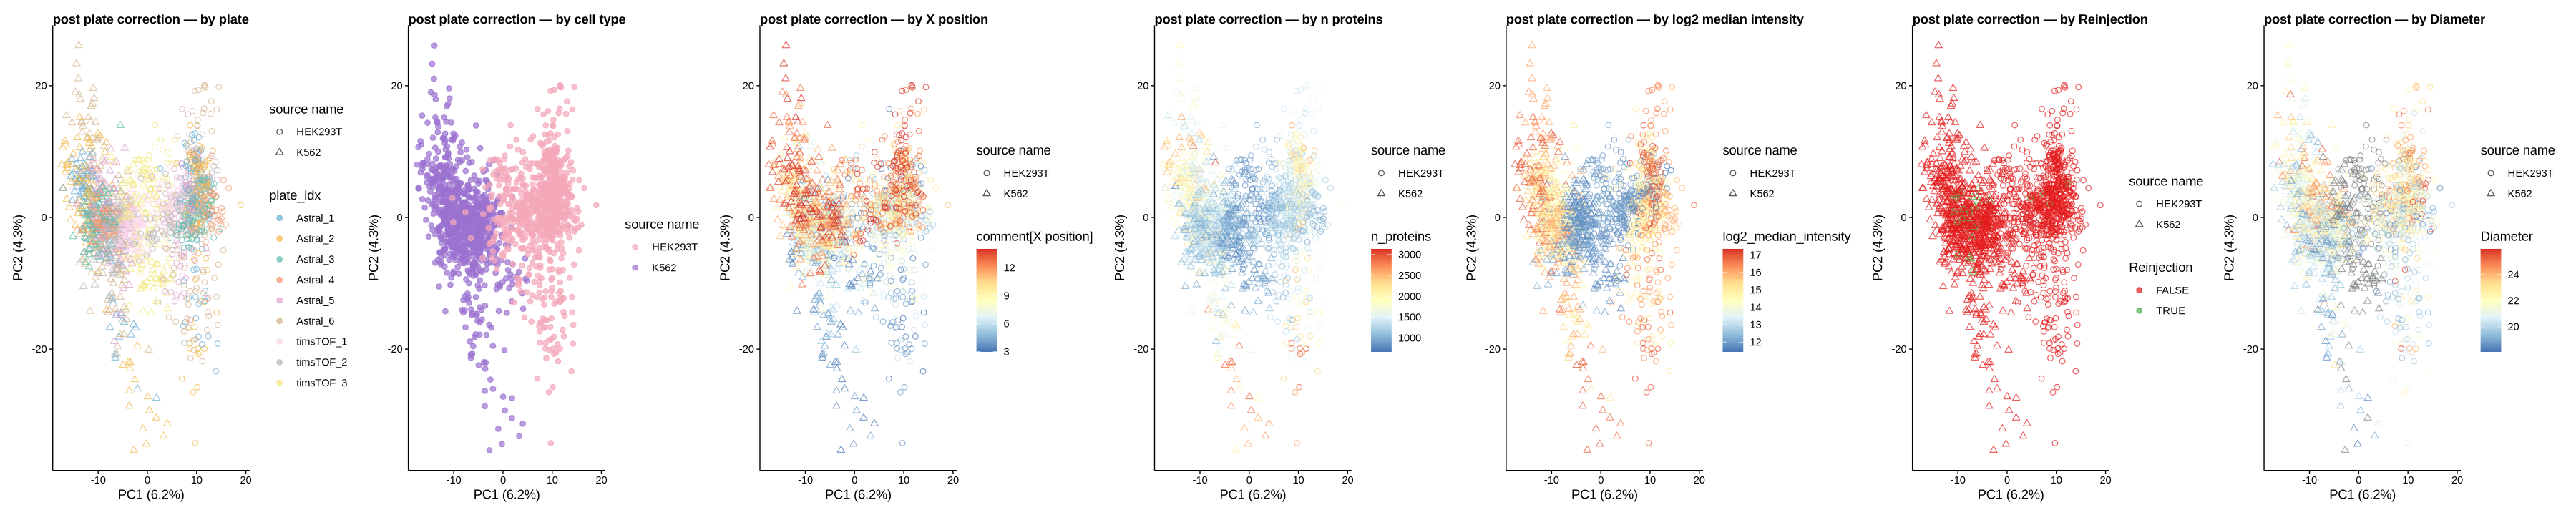

Warning message in brewer.pal(min(n, 9), "Set1"):
“minimal value for n is 3, returning requested palette with 3 different levels
”


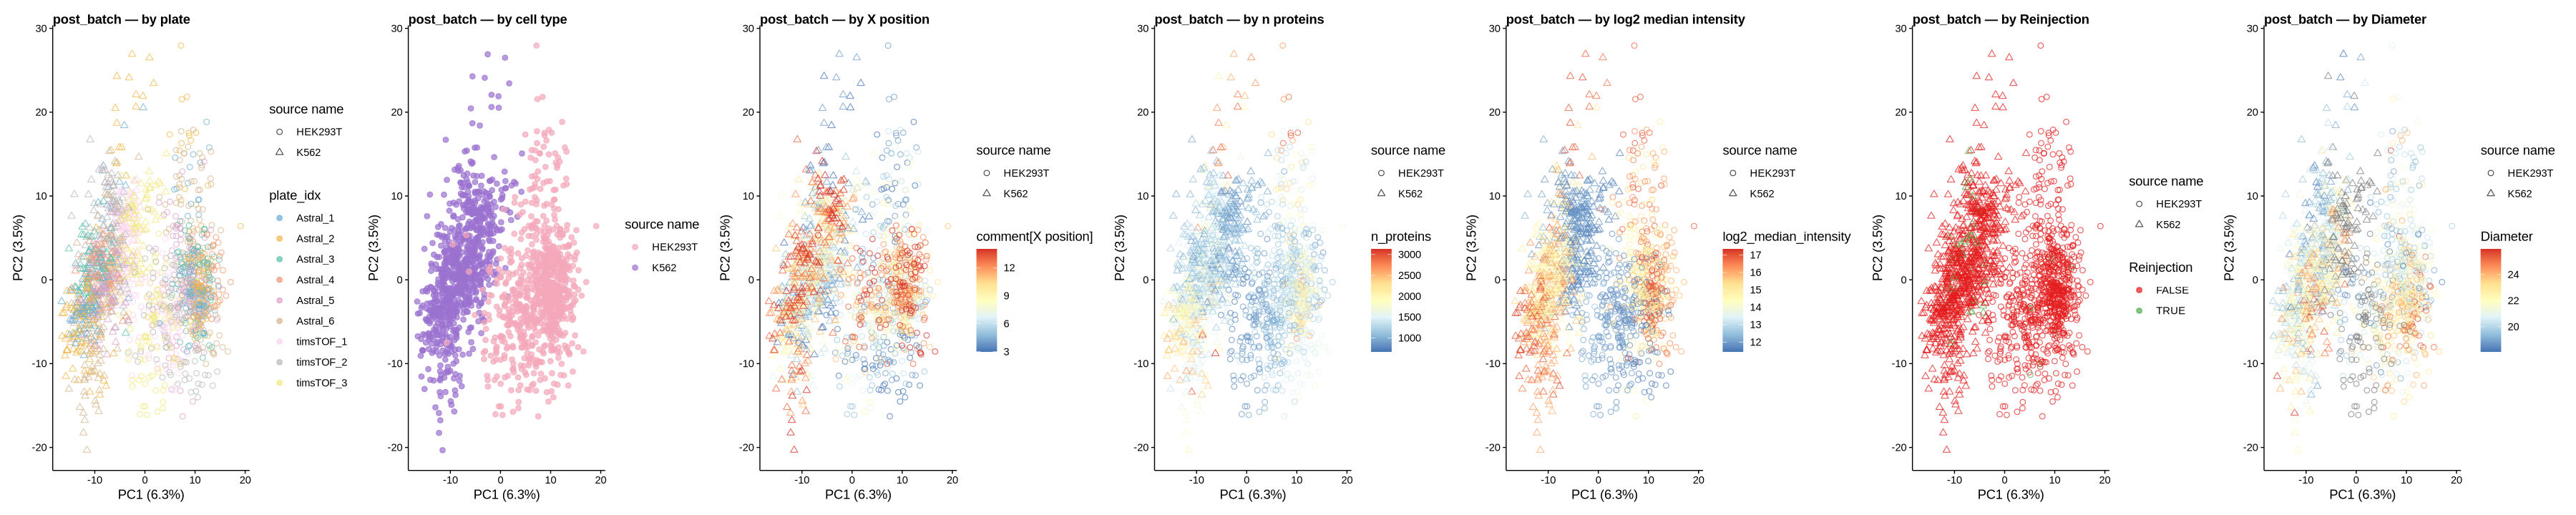

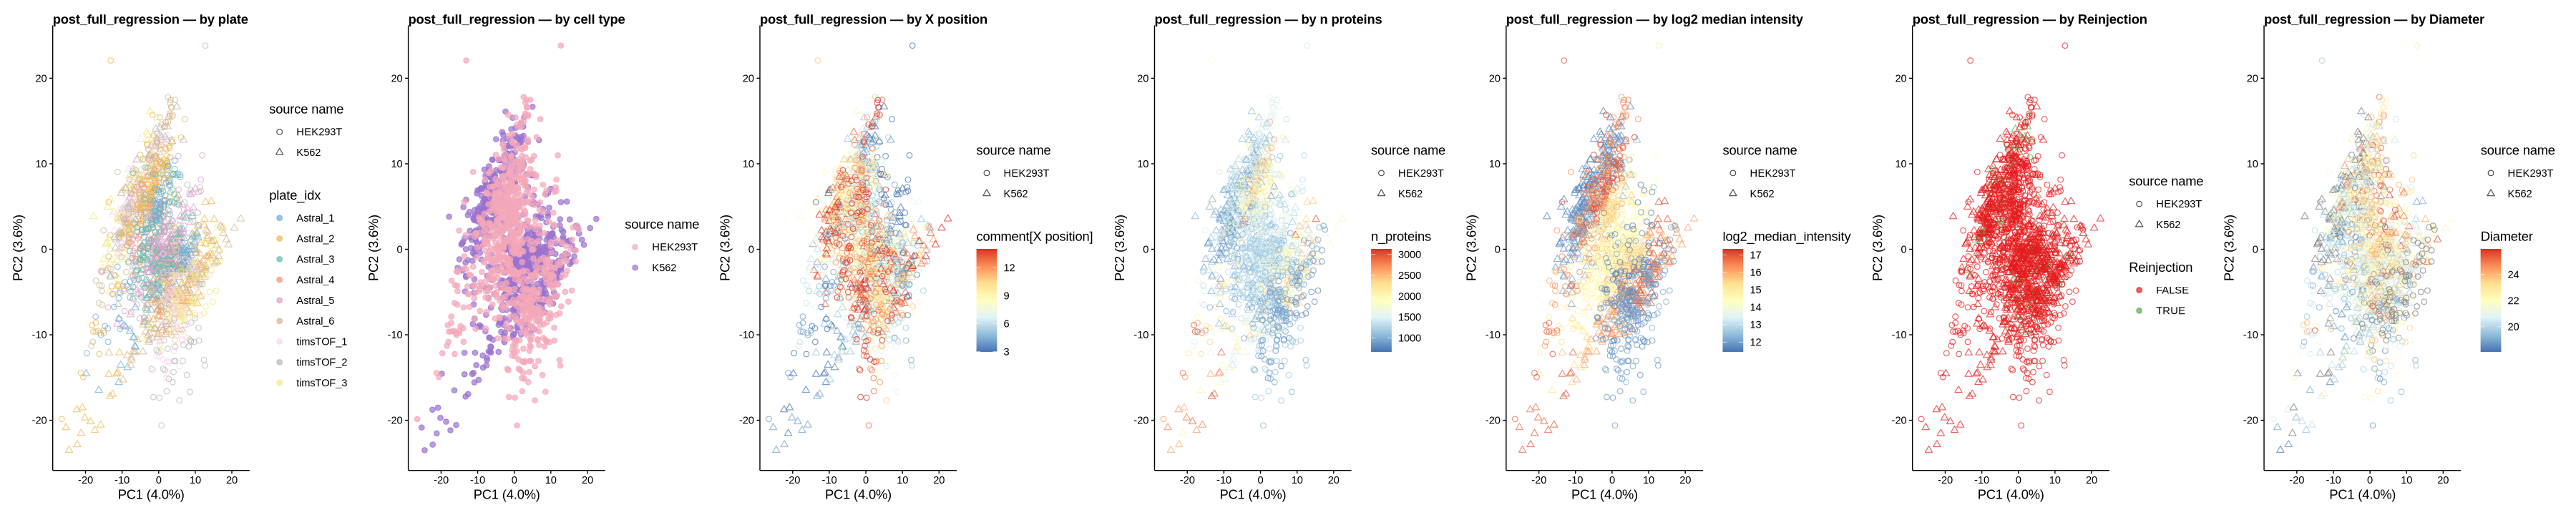

In [18]:
# helper to compute PCA once per matrix
compute_pca <- function(mat) {
    complete <- rowSums(is.na(mat)) == 0
    prcomp(t(mat[complete, ]), scale. = TRUE, center = TRUE)
}


mat_list <- list(
    "raw"                  = expr_mat_impute,
    "post_normalisation"   = res_norm,
    "post plate correction" = res_plate,
    "post_batch"           = res_batch,
    "post_full_regression" = res_all
)

for (nm in names(mat_list)) {
    mat <- mat_list[[nm]]
    cat(sprintf("Computing PCA: %s...\n", nm))
    flush.console()
    pca <- compute_pca(mat)

    colour_vars <- list(
        list(colour = COL_PLATE,        shape = COL_CELL_TYPE, label = "by plate"),
        list(colour = COL_CELL_TYPE,    shape = NULL,          label = "by cell type"),
        list(colour = COL_X_POSITION,   shape = COL_CELL_TYPE, label = "by X position"),
        list(colour = COL_N_PROTEINS,   shape = COL_CELL_TYPE, label = "by n proteins"),
        list(colour = COL_LOG2_MED_INT, shape = COL_CELL_TYPE, label = "by log2 median intensity"),
        list(colour = 'Reinjection',    shape = COL_CELL_TYPE, label = "by Reinjection"),
        list(colour = COL_DIAMETER,     shape = COL_CELL_TYPE, label = "by Diameter")
    )

    panels <- lapply(colour_vars, function(cv) {
        plot_pca(pca, meta,
                 colour_var = cv$colour,
                 shape_var  = cv$shape,
                 title      = sprintf("%s — %s", nm, cv$label),
                 show       = FALSE)
    })

    combined <- Reduce(`|`, panels)
    save_figure(combined, file.path(FIG_OUT, paste0("pca_", nm)), width = 30, height = 6)
    options(repr.plot.width = 30, repr.plot.height = 6)
    print(combined)
    flush.console()
}

## 8. Export

Saves the variance fraction matrices as CSV files for use in downstream analyses or figure generation outside R. The CSV files complement the RDS objects: they are human-readable and can be loaded in Python without an R runtime.

In [16]:
if (!exists("vp_fit"))       vp_fit       <- readRDS(file.path(MODELS_OUT, "vp_fit.rds"))
if (!exists("vp_fit_norm"))  vp_fit_norm  <- readRDS(file.path(MODELS_OUT, "vp_fit_norm.rds"))
if (!exists("vp_fit_batch")) vp_fit_batch <- readRDS(file.path(MODELS_OUT, "vp_fit_batch.rds"))

write.csv(as.data.frame(vp_fit),
          file.path(MODELS_OUT, "variance_fractions_full.csv"),  row.names = TRUE)
write.csv(as.data.frame(vp_fit_norm),
          file.path(MODELS_OUT, "variance_fractions_norm.csv"),  row.names = TRUE)
write.csv(as.data.frame(vp_fit_batch),
          file.path(MODELS_OUT, "variance_fractions_batch.csv"), row.names = TRUE)

cat("Exported:\n")
for (f in c("variance_fractions_full.csv",
            "variance_fractions_norm.csv",
            "variance_fractions_batch.csv")) {
    cat(sprintf("  %s\n", file.path(MODELS_OUT, f)))
}

Exported:
  /home/sam/SCI/SCI/Data/variancePartition/variance_fractions_full.csv
  /home/sam/SCI/SCI/Data/variancePartition/variance_fractions_norm.csv
  /home/sam/SCI/SCI/Data/variancePartition/variance_fractions_batch.csv
